# 01 – Data profile
Purpose: describe the size, class balance and basic quality of the prepared AML data.
Data: `data/processed/full_*` joined on `transaction_id`.
Splits used: the class-balance table covers all four splits; everything else uses **train only**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Find the project folder (the one containing src/analysis) so imports work from this notebook.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "analysis").is_dir())
sys.path.insert(0, str(ROOT))

from src.analysis.data import load_eda_frame, SPLIT_ORDER, LABEL_COLUMN

pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: /Users/yasashwisg/Desktop/ML/following-the-money-aml


In [2]:
everything = load_eda_frame(splits=SPLIT_ORDER)
train = everything[everything["split"] == "train"].copy()

print(f"All splits: {len(everything):,} rows")
print(f"Train only: {len(train):,} rows")

All splits: 5,078,345 rows
Train only: 3,046,861 rows


In [3]:
profile = everything.groupby("split", observed=True)[LABEL_COLUMN].agg(
    transactions="count", laundering="sum"
)
profile["legitimate"] = profile["transactions"] - profile["laundering"]
profile["laundering_rate_%"] = (100 * profile["laundering"] / profile["transactions"]).round(4)
profile["one_in_N"] = (profile["transactions"] / profile["laundering"]).round(0).astype(int)
profile["share_of_rows_%"] = (100 * profile["transactions"] / profile["transactions"].sum()).round(2)

print("Totals:", profile[["transactions", "laundering", "legitimate"]].sum().to_dict())
profile

Totals: {'transactions': 5078345, 'laundering': 5177, 'legitimate': 5073168}


,transactions,laundering,legitimate,laundering_rate_%,one_in_N,share_of_rows_%
split,,,,,,
train,3046861,2297,3044564,0.0754,1326,60.00
val,1015602,1082,1014520,0.1065,939,20.00
test_main,1014774,1143,1013631,0.1126,888,19.98
test_tail,1108,655,453,59.1155,2,0.02


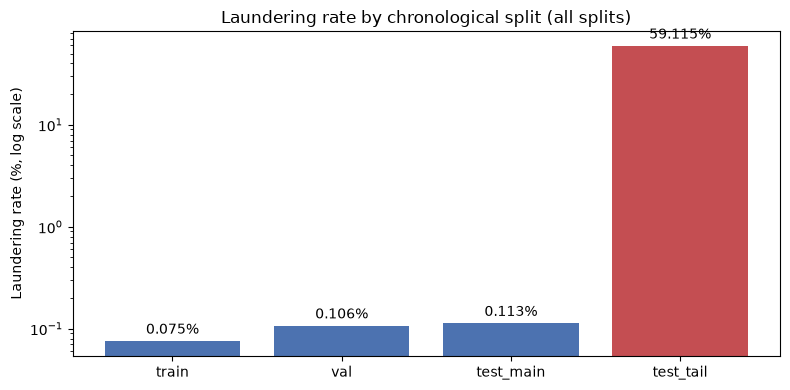

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
colours = ["#4C72B0", "#4C72B0", "#4C72B0", "#C44E52"]  # tail in red: it is the anomaly
bars = ax.bar(profile.index.astype(str), profile["laundering_rate_%"], color=colours)
ax.set_yscale("log")
ax.bar_label(bars, labels=[f"{v:.3f}%" for v in profile["laundering_rate_%"]], padding=3)
ax.set_ylabel("Laundering rate (%, log scale)")
ax.set_title("Laundering rate by chronological split (all splits)")
fig.tight_layout()
plt.show()

In [5]:
print("Missing values per column (train):")
print(train.isna().sum())
print("\nDuplicate transaction_id values:", train["transaction_id"].duplicated().sum())
print("Label values:", sorted(train[LABEL_COLUMN].unique()))

Missing values per column (train):
transaction_id                 0
log_amount_paid                0
payment_currency               0
payment_format                 0
same_bank                      0
sender_txn_count_1h            0
sender_txn_count_24h           0
sender_unique_receivers_24h    0
receiver_txn_count_1h          0
receiver_txn_count_24h         0
receiver_unique_senders_24h    0
is_laundering                  0
split                          0
dtype: int64

Duplicate transaction_id values: 0
Label values: [np.int64(0), np.int64(1)]


In [6]:
NUMERIC = [
    "log_amount_paid",
    "sender_txn_count_1h", "sender_txn_count_24h", "sender_unique_receivers_24h",
    "receiver_txn_count_1h", "receiver_txn_count_24h", "receiver_unique_senders_24h",
]
train[NUMERIC].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_amount_paid,3046861.0,7.46,3.49,0.0,5.16,7.33,9.58,27.16
sender_txn_count_1h,3046861.0,37.72,167.87,0.0,0.00,0.00,1.00,2818.00
sender_txn_count_24h,3046861.0,730.17,3332.70,0.0,1.00,3.00,7.00,26358.00
sender_unique_receivers_24h,3046861.0,320.47,1452.10,0.0,1.00,2.00,3.00,12536.00
receiver_txn_count_1h,3046861.0,0.80,2.38,0.0,0.00,0.00,1.00,88.00
receiver_txn_count_24h,3046861.0,2.46,5.45,0.0,1.00,2.00,3.00,538.00
receiver_unique_senders_24h,3046861.0,1.40,5.16,0.0,1.00,1.00,2.00,538.00


In [7]:
for col in ["payment_format", "payment_currency", "same_bank"]:
    table = train[col].value_counts().to_frame("transactions")
    table["share_%"] = (100 * table["transactions"] / len(train)).round(2)
    print(f"\n=== {col} (train) ===")
    print(table)


=== payment_format (train) ===
                transactions  share_%
payment_format                       
Cheque               1034265    33.95
Credit Card           735295    24.13
Reinvestment          481056    15.79
ACH                   338654    11.11
Cash                  273461     8.98
Wire                   96944     3.18
Bitcoin                87186     2.86

=== payment_currency (train) ===
                   transactions  share_%
payment_currency                        
US Dollar               1137105    37.32
Euro                     702661    23.06
Swiss Franc              140970     4.63
Yuan                     128298     4.21
Shekel                   115106     3.78
Rupee                    114097     3.74
UK Pound                 108201     3.55
Yen                       93206     3.06
Ruble                     92881     3.05
Bitcoin                   87173     2.86
Canadian Dollar           83749     2.75
Australian Dollar         81877     2.69
Mexican Peso      

## What I found
- The prepared data has 5,078,345 transactions with no missing values, no duplicate IDs and labels of only 0/1 (train checked).
- Laundering is extremely rare: 0.075% in train (1 in 1,326). Val (0.107%) and test_main (0.113%) are slightly higher, so the rate drifts up over time.
- test_tail is a clear anomaly: 59% laundering in 1,108 transactions, shown in red on the log-scale chart.
- Sender activity counts are heavily right-skewed (24h count: median 3, mean 730, max 26,358), which points to a few very busy hub accounts. Receiver counts are much smaller. Medians and rank-based tests will therefore be used instead of means and t-tests.
- Amounts are in 15 different currencies and are not converted, so amount comparisons will be made within a currency.
- ACH is only 11% of train payments; Cheque (34%) and Credit Card (24%) are the most common formats. 80% of payments are between different banks.